# Telecom Customer Churn — Exploratory Data Analysis

Исследование факторов, связанных с оттоком клиентов телеком-компании.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency

## 1. Загрузка и знакомство с данными

Загрузим данные о клиентах телеком-компании и посмотрим на первые строки таблицы.

In [2]:
df = pd.read_csv("../data/raw/telecom_churn.csv")

df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


## 2. Проверка качества данных

Проверим размер таблицы, типы данных, наличие пропусков и полных дубликатов.

In [3]:
print("Размер таблицы:", df.shape)

print("\nТипы данных:")
df.info()

print("\nПропуски по столбцам:")
print(df.isna().sum())

print("\nКоличество полных дубликатов:", df.duplicated().sum())

Размер таблицы: (3333, 20)

Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14 

## 3. Распределение оттока

Посмотрим, сколько клиентов ушло и сколько осталось, а также оценим соотношение этих групп.

In [4]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

print("\nДоли клиентов, %:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
False    2850
True      483
Name: count, dtype: int64

Доли клиентов, %:
Churn
False    85.51
True     14.49
Name: proportion, dtype: float64


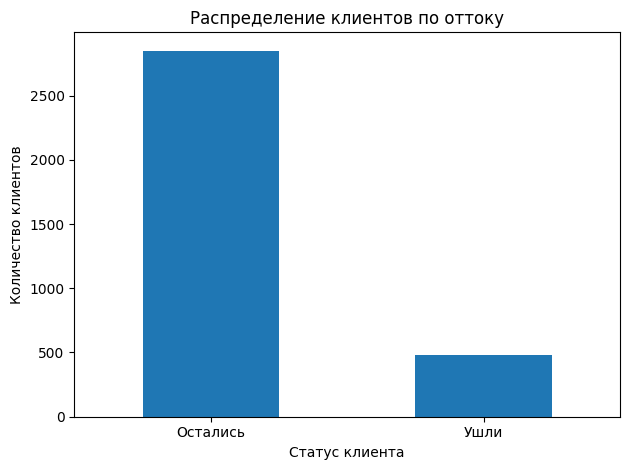

In [5]:
churn_counts.rename({
    False: "Остались",
    True: "Ушли"
}).plot(
    kind="bar",
    rot=0,
    title="Распределение клиентов по оттоку"
)

plt.xlabel("Статус клиента")
plt.ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

## 4. Сравнение дневных показателей

Сравним средние значения, медианы и стандартные отклонения дневной платы, количества минут и числа звонков у ушедших и оставшихся клиентов.

In [6]:
df.groupby("Churn")[
    ["Total day charge", "Total day minutes", "Total day calls"]
].agg(["mean", "median", "std"]).round(2)

Total day charge               Total day minutes                \
                  mean median    std              mean median    std   
Churn                                                                  
False            29.78  30.12   8.53            175.18  177.2  50.18   
True             35.18  36.99  11.73            206.91  217.6  69.00   

      Total day calls                
                 mean median    std  
Churn                                
False          100.28  100.0  19.80  
True           101.34  103.0  21.58

## 5. Статистические тесты

Проверим, отличается ли средняя дневная плата у ушедших и оставшихся клиентов, а также существует ли статистически значимая связь между международным тарифным планом и оттоком.

In [7]:
churned = df.loc[df["Churn"], "Total day charge"]
retained = df.loc[~df["Churn"], "Total day charge"]

result = ttest_ind(
    churned,
    retained,
    equal_var=False
)

print(f"Среднее у ушедших: {churned.mean():.2f}")
print(f"Среднее у оставшихся: {retained.mean():.2f}")
print(f"Разница средних: {churned.mean() - retained.mean():.2f}")
print(f"t-статистика: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.6g}")

Среднее у ушедших: 35.18
Среднее у оставшихся: 29.78
Разница средних: 5.40
t-статистика: 9.684
p-value: 1.21988e-20


In [8]:
contingency_table = pd.crosstab(
    df["International plan"],
    df["Churn"]
)

print("Таблица сопряжённости:")
print(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"\nХи-квадрат: {chi2:.3f}")
print(f"Степени свободы: {dof}")
print(f"p-value: {p_value:.6g}")

Таблица сопряжённости:
Churn               False  True 
International plan              
No                   2664    346
Yes                   186    137

Хи-квадрат: 222.566
Степени свободы: 1
p-value: 2.49311e-50


## 6. Визуальный анализ факторов оттока

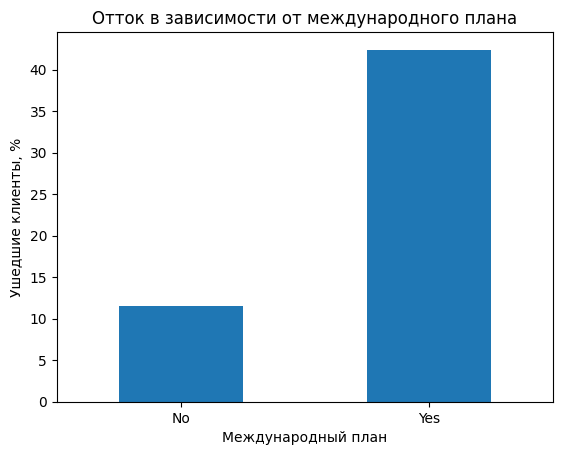

In [9]:
churn_by_intl_plan = (
    df.groupby("International plan")["Churn"]
    .mean()
    .mul(100)
)

churn_by_intl_plan.plot(
    kind="bar",
    rot=0
)

plt.title("Отток в зависимости от международного плана")
plt.xlabel("Международный план")
plt.ylabel("Ушедшие клиенты, %")
plt.show()

Клиенты с международным тарифным планом уходят значительно чаще: доля оттока составляет около 42,4% против 11,5% среди клиентов без такого плана. Разница согласуется с результатами критерия хи-квадрат, который выявил статистически значимую связь между наличием международного плана и оттоком. Однако это наблюдаемая связь, а не доказательство причинно-следственной зависимости.

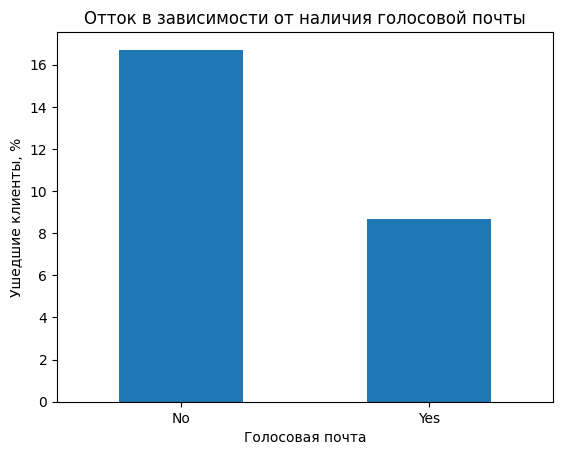

In [10]:
churn_by_voicemail = (
    df.groupby("Voice mail plan")["Churn"]
    .mean()
    .mul(100)
)

churn_by_voicemail.plot(
    kind="bar",
    rot=0
)

plt.title("Отток в зависимости от наличия голосовой почты")
plt.xlabel("Голосовая почта")
plt.ylabel("Ушедшие клиенты, %")
plt.show()

Клиенты без подключённой голосовой почты уходят чаще: доля оттока составляет 16,72% против 8,68% среди клиентов с голосовой почтой. Таким образом, отток в первой группе примерно в 1,9 раза выше. Это наблюдаемая связь, которая сама по себе не доказывает причинно-следственную зависимость.

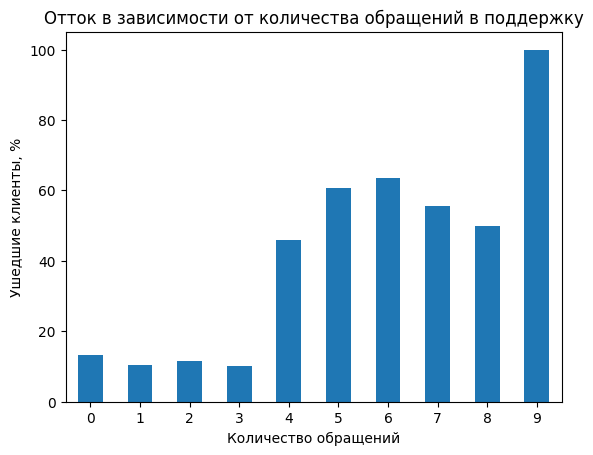

In [11]:
churn_by_support = (
    df.groupby("Customer service calls")["Churn"]
    .mean()
    .mul(100)
)

churn_by_support.plot(
    kind="bar",
    rot=0
)

plt.title("Отток в зависимости от количества обращений в поддержку")
plt.xlabel("Количество обращений")
plt.ylabel("Ушедшие клиенты, %")
plt.show()

При 0–3 обращениях в службу поддержки доля оттока составляет примерно 10–13%. При 4 и более обращениях она заметно возрастает. Это может указывать на связь между частыми обращениями и риском ухода клиента, однако в группах с большим числом обращений мало наблюдений, поэтому оценки оттока там менее устойчивы. По этим данным нельзя утверждать, что обращения в поддержку сами по себе вызывают отток.

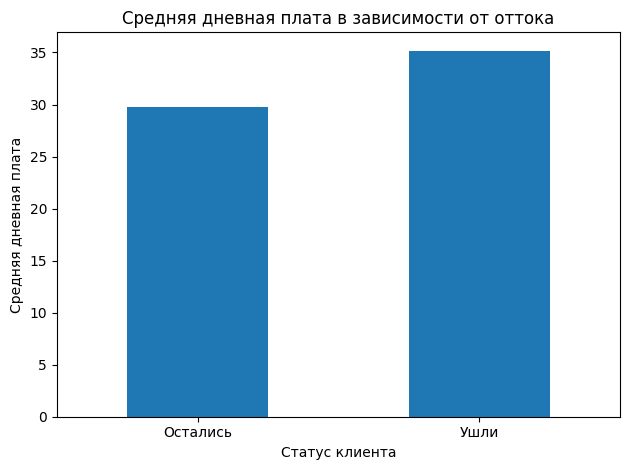

In [12]:
df.groupby("Churn")["Total day charge"].mean().rename({
    False: "Остались",
    True: "Ушли"
}).plot(
    kind="bar",
    rot=0
)

plt.title("Средняя дневная плата в зависимости от оттока")
plt.xlabel("Статус клиента")
plt.ylabel("Средняя дневная плата")
plt.tight_layout()
plt.show()

Средняя дневная плата у ушедших клиентов составляет 35,18 против 29,78 у оставшихся — примерно на 18,1% выше. Разница статистически значима по результатам t-теста Уэлча (p < 0,001). При этом дневная плата связана с количеством использованных минут, поэтому эти показатели не следует считать двумя независимыми факторами оттока.

## 7. Общие выводы

В ходе анализа данных о 3333 клиентах выявлено несколько факторов, связанных с оттоком:

1. **Международный тарифный план.** Доля оттока среди клиентов с международным планом составляет 42,41%, без него — 11,50%. Среди рассмотренных в анализе категориальных признаков здесь наблюдается наиболее заметная разница в долях оттока.
2. **Голосовая почта.** Среди клиентов без голосовой почты отток составляет 16,72%, а среди клиентов с ней — 8,68%.
3. **Обращения в службу поддержки.** При четырёх и более обращениях доля оттока заметно возрастает. Однако в этих группах мало наблюдений, поэтому результаты следует интерпретировать осторожно.
4. **Дневная плата.** Средняя дневная плата у ушедших клиентов составляет 35,18 против 29,78 у оставшихся. Разница статистически значима по результатам t-теста Уэлча, однако это не означает, что дневная плата сама по себе вызывает отток.

### Ограничения анализа

Результаты показывают статистические связи, но не доказывают причинно-следственную зависимость. Дневная плата связана с количеством использованных минут, поэтому эти признаки не следует рассматривать как независимые объяснения оттока. Для более полного анализа полезно дополнительно учитывать сочетание факторов и характеристики клиентов.